# v8 analysis (one GPU): hardcore lesion + related vs distant languages
**Run All.** One-GPU machine: training is paused while this runs.
Order: (1) lesion on the old distant models (~2 h) → (2) distant run, phases 10–30 → (3) related (v8) run, every phase that exists by then → (4) lesion on v8 → (5) comparison.
Results: `analysis/v8/`. Every cell prints as it goes.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"          # one-GPU machine
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)
    for f in ["phases.jsonl"]:
        if not os.path.exists(f"runs/{run}/{f}") and f"{run}/{f}" in FILES:
            hf_hub_download(HF_REPO, f"{run}/{f}", local_dir="runs")

def run(langset, *cmd):
    env = {**os.environ, "CML_LANGSET": langset}
    p = subprocess.Popen([sys.executable, "-u", "analysis_v8.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

V8 = "v8_indic_continual_s0"
DISTANT_LESION = ("continual=v4b_continual_s0:10,30,45,60:all;hindi=v4b_only_hi_s0:30,60:hi;"
                  "mixed=v6b_mixed_s0:30,60:all;push=v6_hi_push0.6_from30:40:hi")
print("v8 checkpoints so far:", sorted(glob.glob(f"runs/{V8}/ckpt/p*.pt"))[-1:])

v8 checkpoints so far: []


In [2]:
# download what the distant analyses need (about 25 checkpoints, a few minutes)
need = json.loads(subprocess.check_output([sys.executable, "analysis_v8.py", "--list", "--parts", "related", "lesion",
                                           "--run", "v4b_continual_s0", "--anchor", "10", "--upto", "30", "--models", DISTANT_LESION]))
for r, phs in need.items():
    print(r, phs); get(r, phs)
print("ok")

v4b_continual_s0 [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 45, 60]


p010_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p011_zh.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p012_ar.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p013_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p014_zh.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

... (27 outputs left out)

v6_hi_push0.6_from30 [40]


p040_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

phases.jsonl:   0%|          | 0.00/13.8k [00:00<?, ?B/s]

ok


In [3]:
# v8 (related) needs: its data + tokenizer_v8 + its checkpoints from HF. prep skips whatever already exists.
# If tokenizer_v8 is NOT on this machine, prep re-makes it. The check below makes sure it is IDENTICAL to the one used
# for training (otherwise every v8 number would be wrong).
subprocess.run([sys.executable, "-u", "prep_indic_data.py"], check=True, env={**os.environ, "CML_LANGSET": "indic"})
v8_files = sorted(f for f in FILES if f.startswith(f"{V8}/ckpt/"))
print("v8 checkpoints on HF:", len(v8_files), "| last:", v8_files[-1] if v8_files else None)
get(V8, [int(os.path.basename(f)[1:4]) for f in v8_files if 10 <= int(os.path.basename(f)[1:4]) <= 30])
check = '''
import json, glob
from common_v8 import *
rows = {json.loads(l)["phase"]: json.loads(l) for l in open("runs/v8_indic_continual_s0/phases.jsonl") if l.strip()}
ph = max(p for p in rows if glob.glob(f"runs/v8_indic_continual_s0/ckpt/p{p:03d}_*.pt"))
m, c = load_model(glob.glob(f"runs/v8_indic_continual_s0/ckpt/p{ph:03d}_*.pt")[0])
for l in LANGS:
    v = val_loss(m, load_pairs(P(f"data/en-{l}/val.jsonl"), l)[:2000], l, masked=True)
    print(f"phase {ph} {l}: val loss now {v:.4f} | logged during training {rows[ph]['val_masked'][l]:.4f} | difference {abs(v - rows[ph]['val_masked'][l]):.4f}")
print("OK: same tokenizer and data" if True else "")
'''
subprocess.run([sys.executable, "-c", check], env={**os.environ, "CML_LANGSET": "indic", "CUDA_VISIBLE_DEVICES": GPU})
print("differences should be about 0.000-0.002. If they are bigger than 0.01: STOP and tell Claude.")

Hindi training pairs: 993,016 -> Gujarati and Punjabi get exactly the same number


Generating dev split: 997 examples [00:00, 79262.31 examples/s]
Generating devtest split: 1012 examples [00:00, 48813.04 examples/s]


wrote data/flores/dev.gu.jsonl 997
wrote data/flores/devtest.gu.jsonl 1012


Generating dev split: 997 examples [00:00, 74543.14 examples/s]
Generating devtest split: 1012 examples [00:00, 80406.06 examples/s]


wrote data/flores/dev.pa.jsonl 997
wrote data/flores/devtest.pa.jsonl 1012
  hi: 1.37 pieces per word (2,000 validation sentences)
  gu: 1.52 pieces per word (2,000 validation sentences)
  pa: 1.31 pieces per word (2,000 validation sentences)
data ready: {'hi': 993016, 'gu': 993016, 'pa': 993016}
v8 checkpoints on HF: 17 | last: v8_indic_continual_s0/ckpt/p016_hi.pt


p010_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

... (4 outputs left out)

p015_pa.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p016_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

phases.jsonl:   0%|          | 0.00/7.92k [00:00<?, ?B/s]

phase 16 hi: val loss now 1.3011 | logged during training 1.3010 | difference 0.0001
phase 16 gu: val loss now 4.1962 | logged during training 4.1961 | difference 0.0001
phase 16 pa: val loss now 3.3692 | logged during training 3.3692 | difference 0.0000
OK: same tokenizer and data
differences should be about 0.000-0.002. If they are bigger than 0.01: STOP and tell Claude.


In [4]:
# (1) HARDCORE LESION on the distant models (Hindi / Chinese / Arabic). About 10-15 min per checkpoint, 9 checkpoints.
run("distant", "--parts", "lesion", "--models", DISTANT_LESION, "--tag", "distant")

=== HARDCORE LESION (distant: hi, zh, ar) | tau 0.2 | doses (0.05, 0.1, 0.2) of each layer | 3 repeats | loss on 300 val pairs/lang, chrF on 150 FLORES sentences/lang ===
  'matched' = task neurons with the same average activity, firing rate and outgoing weight size as the self neurons
  continual p10 (hi, 174s) | ONE layer, 10%: loss rise self 0.0089 matched 0.0052 random 0.0043 | ALL layers 10%: chrF 22.1 -> self 20.1 matched 22.2 random 21.8
  continual p30 (ar, 169s) | ONE layer, 10%: loss rise self 0.0084 matched 0.0045 random 0.0077 | ALL layers 10%: chrF 23.1 -> self 21.4 matched 23.3 random 23.2
  continual p45 (ar, 172s) | ONE layer, 10%: loss rise self 0.0076 matched 0.0070 random 0.0057 | ALL layers 10%: chrF 23.2 -> self 21.5 matched 23.5 random 23.2
  continual p60 (ar, 171s) | ONE layer, 10%: loss rise self 0.0081 matched 0.0048 random 0.0052 | ALL layers 10%: chrF 21.6 -> self 21.6 matched 21.7 random 21.6
  hindi p30 (hi, 58s) | ONE layer, 10%: loss rise self 0.0167 mat

In [5]:
# (2) distant continual run: anchor phase 10, every phase 11-30 (same phase numbers as the related run)
run("distant", "--parts", "related", "--run", "v4b_continual_s0", "--anchor", "10", "--upto", "30", "--tag", "distant")

=== v4b_continual_s0 (distant: hi, zh, ar) | anchor phase 10 | later phases 11..30 | tau 0.2 ===
  anchor phase 10 was trained on hi
  chance (noise 0.15): other neurons change   4.5 | self changes  28.2% less
  chance (noise 0.3): other neurons change  16.9 | self changes  26.7% less
  chance (noise 0.45): other neurons change  34.7 | self changes  23.3% less
  chance (noise 0.6): other neurons change  55.0 | self changes  18.6% less
  chance (noise 0.8): other neurons change  76.0 | self changes  18.6% less
  chance (noise 1.0): other neurons change  87.6 | self changes  12.7% less
  p10->p11 (hi->zh, DIFF): task change  48.4 | self changes  17.4% less (chance 20.2%) | self =  50% of layer | phase-10 self neurons back in the self: enc  81% dec  65%
  p10->p12 (hi->ar, DIFF): task change  54.3 | self changes  13.9% less (chance 18.8%) | self =  57% of layer | phase-10 self neurons back in the self: enc  80% dec  77%
  p10->p13 (hi->hi, SAME): task change  24.4 | self changes  31.1% le

In [6]:
# (3) related run (Hindi / Gujarati / Punjabi): anchor phase 10, every phase that exists NOW (training is still going)
last = max(int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{V8}/ckpt/p*.pt"))
print("v8 phases available up to", last)
run("indic", "--parts", "related", "--run", V8, "--anchor", "10", "--upto", str(min(last, 30)), "--tag", "indic")

v8 phases available up to 16
=== v8_indic_continual_s0 (indic: hi, gu, pa) | anchor phase 10 | later phases 11..16 | tau 0.2 ===
  anchor phase 10 was trained on hi
  chance (noise 0.15): other neurons change   4.2 | self changes  27.5% less
  chance (noise 0.3): other neurons change  16.1 | self changes  26.2% less
  chance (noise 0.45): other neurons change  34.0 | self changes  23.3% less
  chance (noise 0.6): other neurons change  54.9 | self changes  19.4% less
  chance (noise 0.8): other neurons change  76.2 | self changes  19.2% less
  chance (noise 1.0): other neurons change  88.4 | self changes   9.1% less
  p10->p11 (hi->gu, DIFF): task change  35.0 | self changes  23.3% less (chance 23.1%) | self =  54% of layer | phase-10 self neurons back in the self: enc  80% dec  81%
  p10->p12 (hi->pa, DIFF): task change  39.4 | self changes  23.6% less (chance 22.3%) | self =  55% of layer | phase-10 self neurons back in the self: enc  80% dec  82%
  p10->p13 (hi->hi, SAME): task chang

In [7]:
# (4) lesion on the related run: phase 10 and the latest Hindi phase (Hindi phases = 1, 4, 7, 10, 13, ...)
last = max(int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{V8}/ckpt/p*.pt"))
last_hi = max(p for p in range(10, last + 1) if (p - 1) % 3 == 0)
print("lesion on v8 phases 10 and", last_hi)
run("indic", "--parts", "lesion", "--models", f"related={V8}:10,{last_hi}:all", "--tag", "indic")

lesion on v8 phases 10 and 16
=== HARDCORE LESION (indic: hi, gu, pa) | tau 0.2 | doses (0.05, 0.1, 0.2) of each layer | 3 repeats | loss on 300 val pairs/lang, chrF on 150 FLORES sentences/lang ===
  'matched' = task neurons with the same average activity, firing rate and outgoing weight size as the self neurons
  related p10 (hi, 172s) | ONE layer, 10%: loss rise self 0.0144 matched 0.0065 random 0.0045 | ALL layers 10%: chrF 40.5 -> self 36.7 matched 40.8 random 40.2
  related p16 (hi, 164s) | ONE layer, 10%: loss rise self 0.0168 matched 0.0056 random 0.0052 | ALL layers 10%: chrF 43.4 -> self 39.1 matched 42.6 random 43.0

  MATCHING CHECK (10% dose, averages over layers): the matched set should look like the self set
  related p10: self: activity -0.022 firing 0.07 weight 0.83 | matched: activity -0.029 firing 0.07 weight 0.82 | random: activity -0.037 firing 0.06 weight 0.80
  related p16: self: activity -0.024 firing 0.06 weight 0.81 | matched: activity -0.029 firing 0.06 weigh

=== RELATED (Hindi, Gujarati, Punjabi) vs DISTANT (Hindi, Chinese, Arabic), same anchor, phases up to 16 ===
            language    task change  self less  chance  above chance  self back enc  self back dec
  indic     DIFFERENT          39.0      23.7%   22.4%         +1.3            79%            81%
  indic     SAME               23.2      29.3%   25.1%         +4.3            83%            86%
  distant   DIFFERENT          52.8      15.8%   19.2%         -3.4            79%            71%
  distant   SAME               28.3      30.8%   24.5%         +6.3            83%            83%
  indic: average chrF lost by a language when ANOTHER language is trained for one phase: 8.0 points
  distant: average chrF lost by a language when ANOTHER language is trained for one phase: 17.9 points
finished
exit code 0

============================== lesion_distant ==============================
=== HARDCORE LESION (distant: hi, zh, ar) | tau 0.2 | doses (0.05, 0.1, 0.2) of each layer | 3 rep

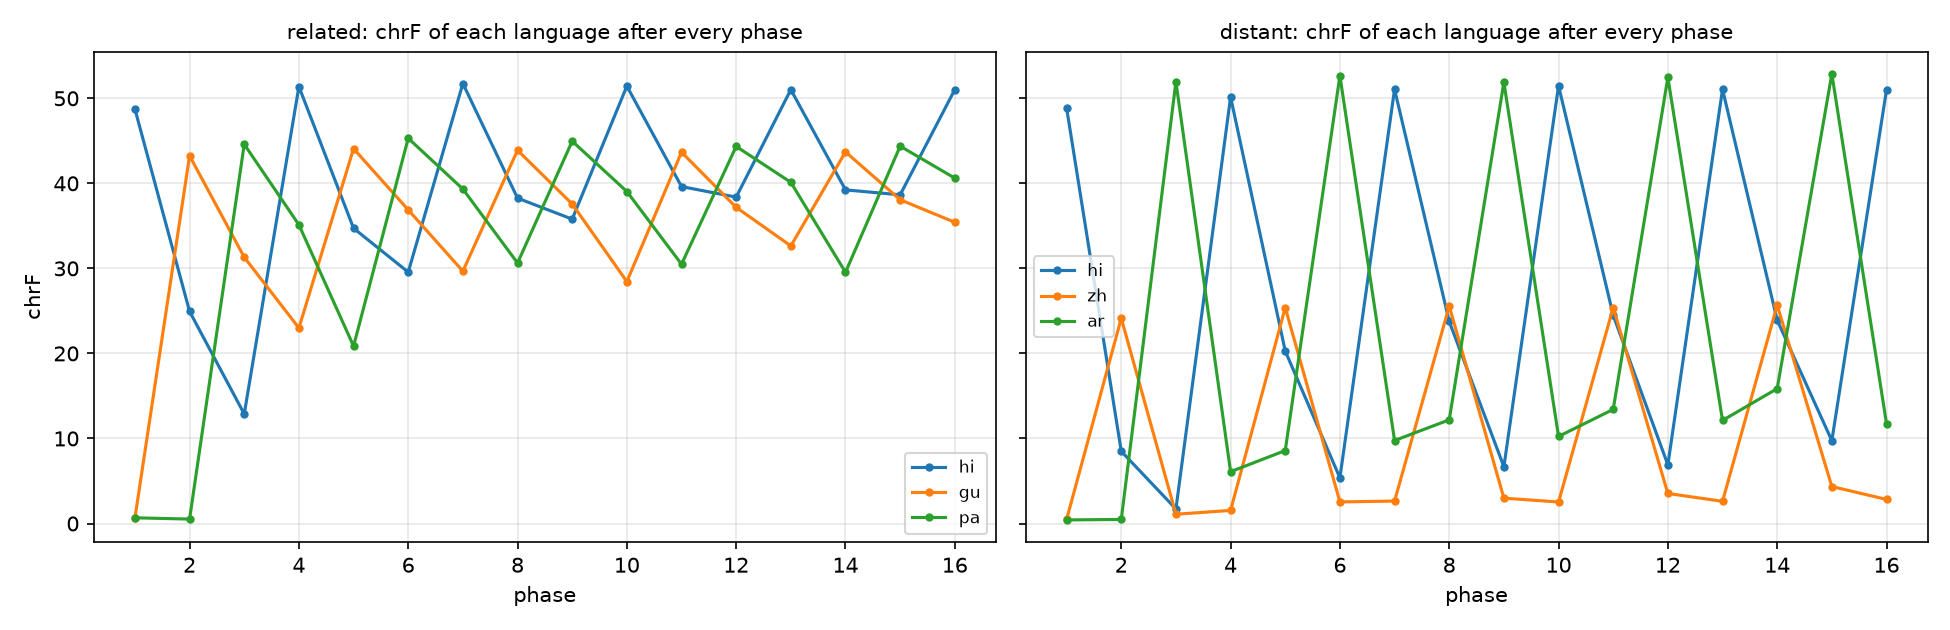

analysis/v8/compare_v8/related_vs_distant.png


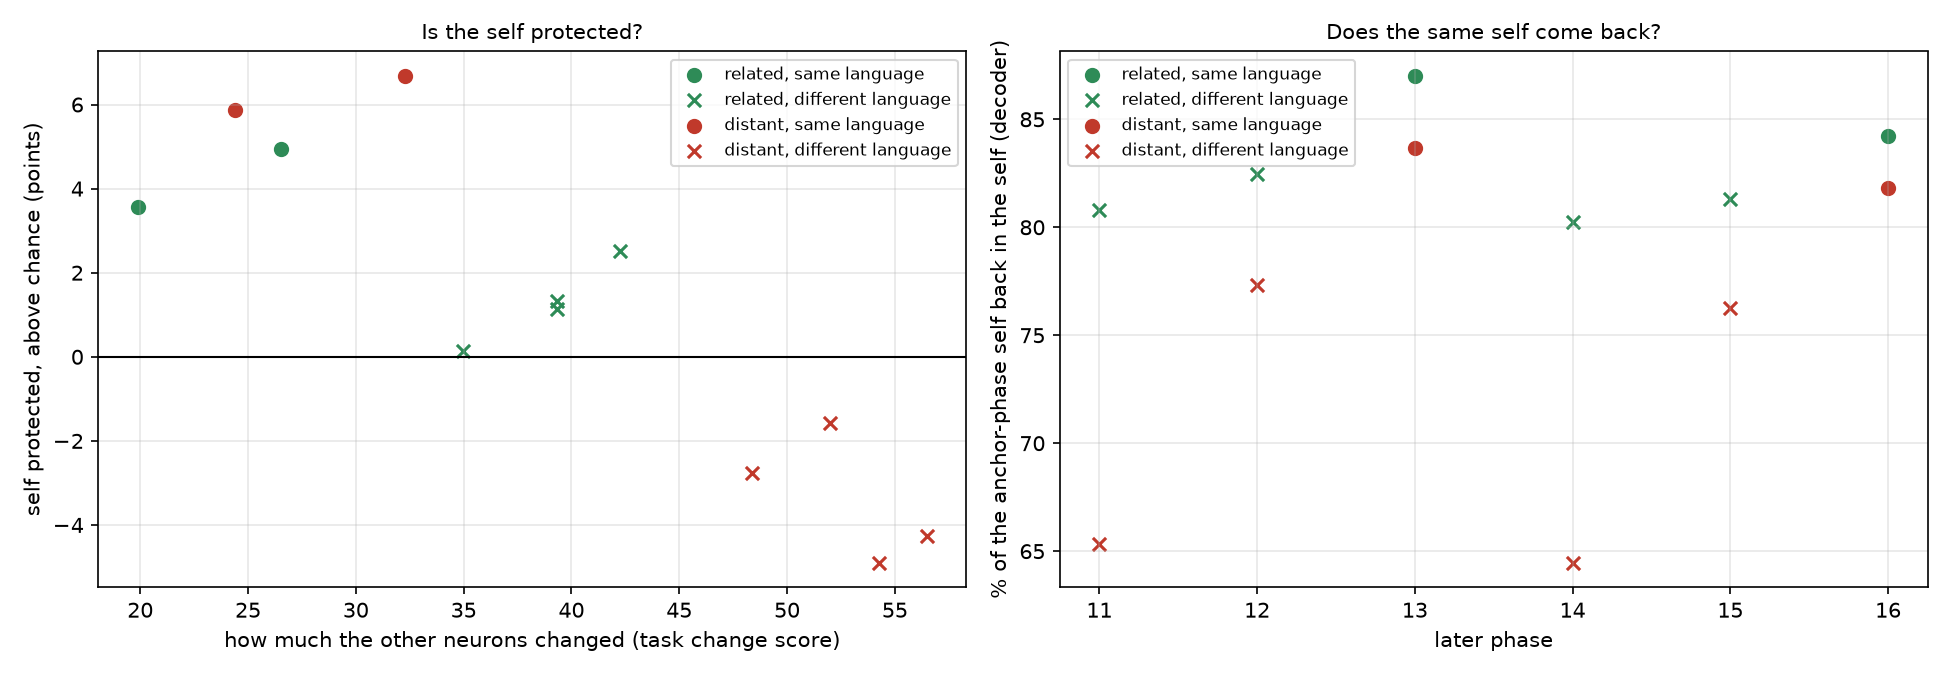

analysis/v8/lesion_distant/dose_response.png


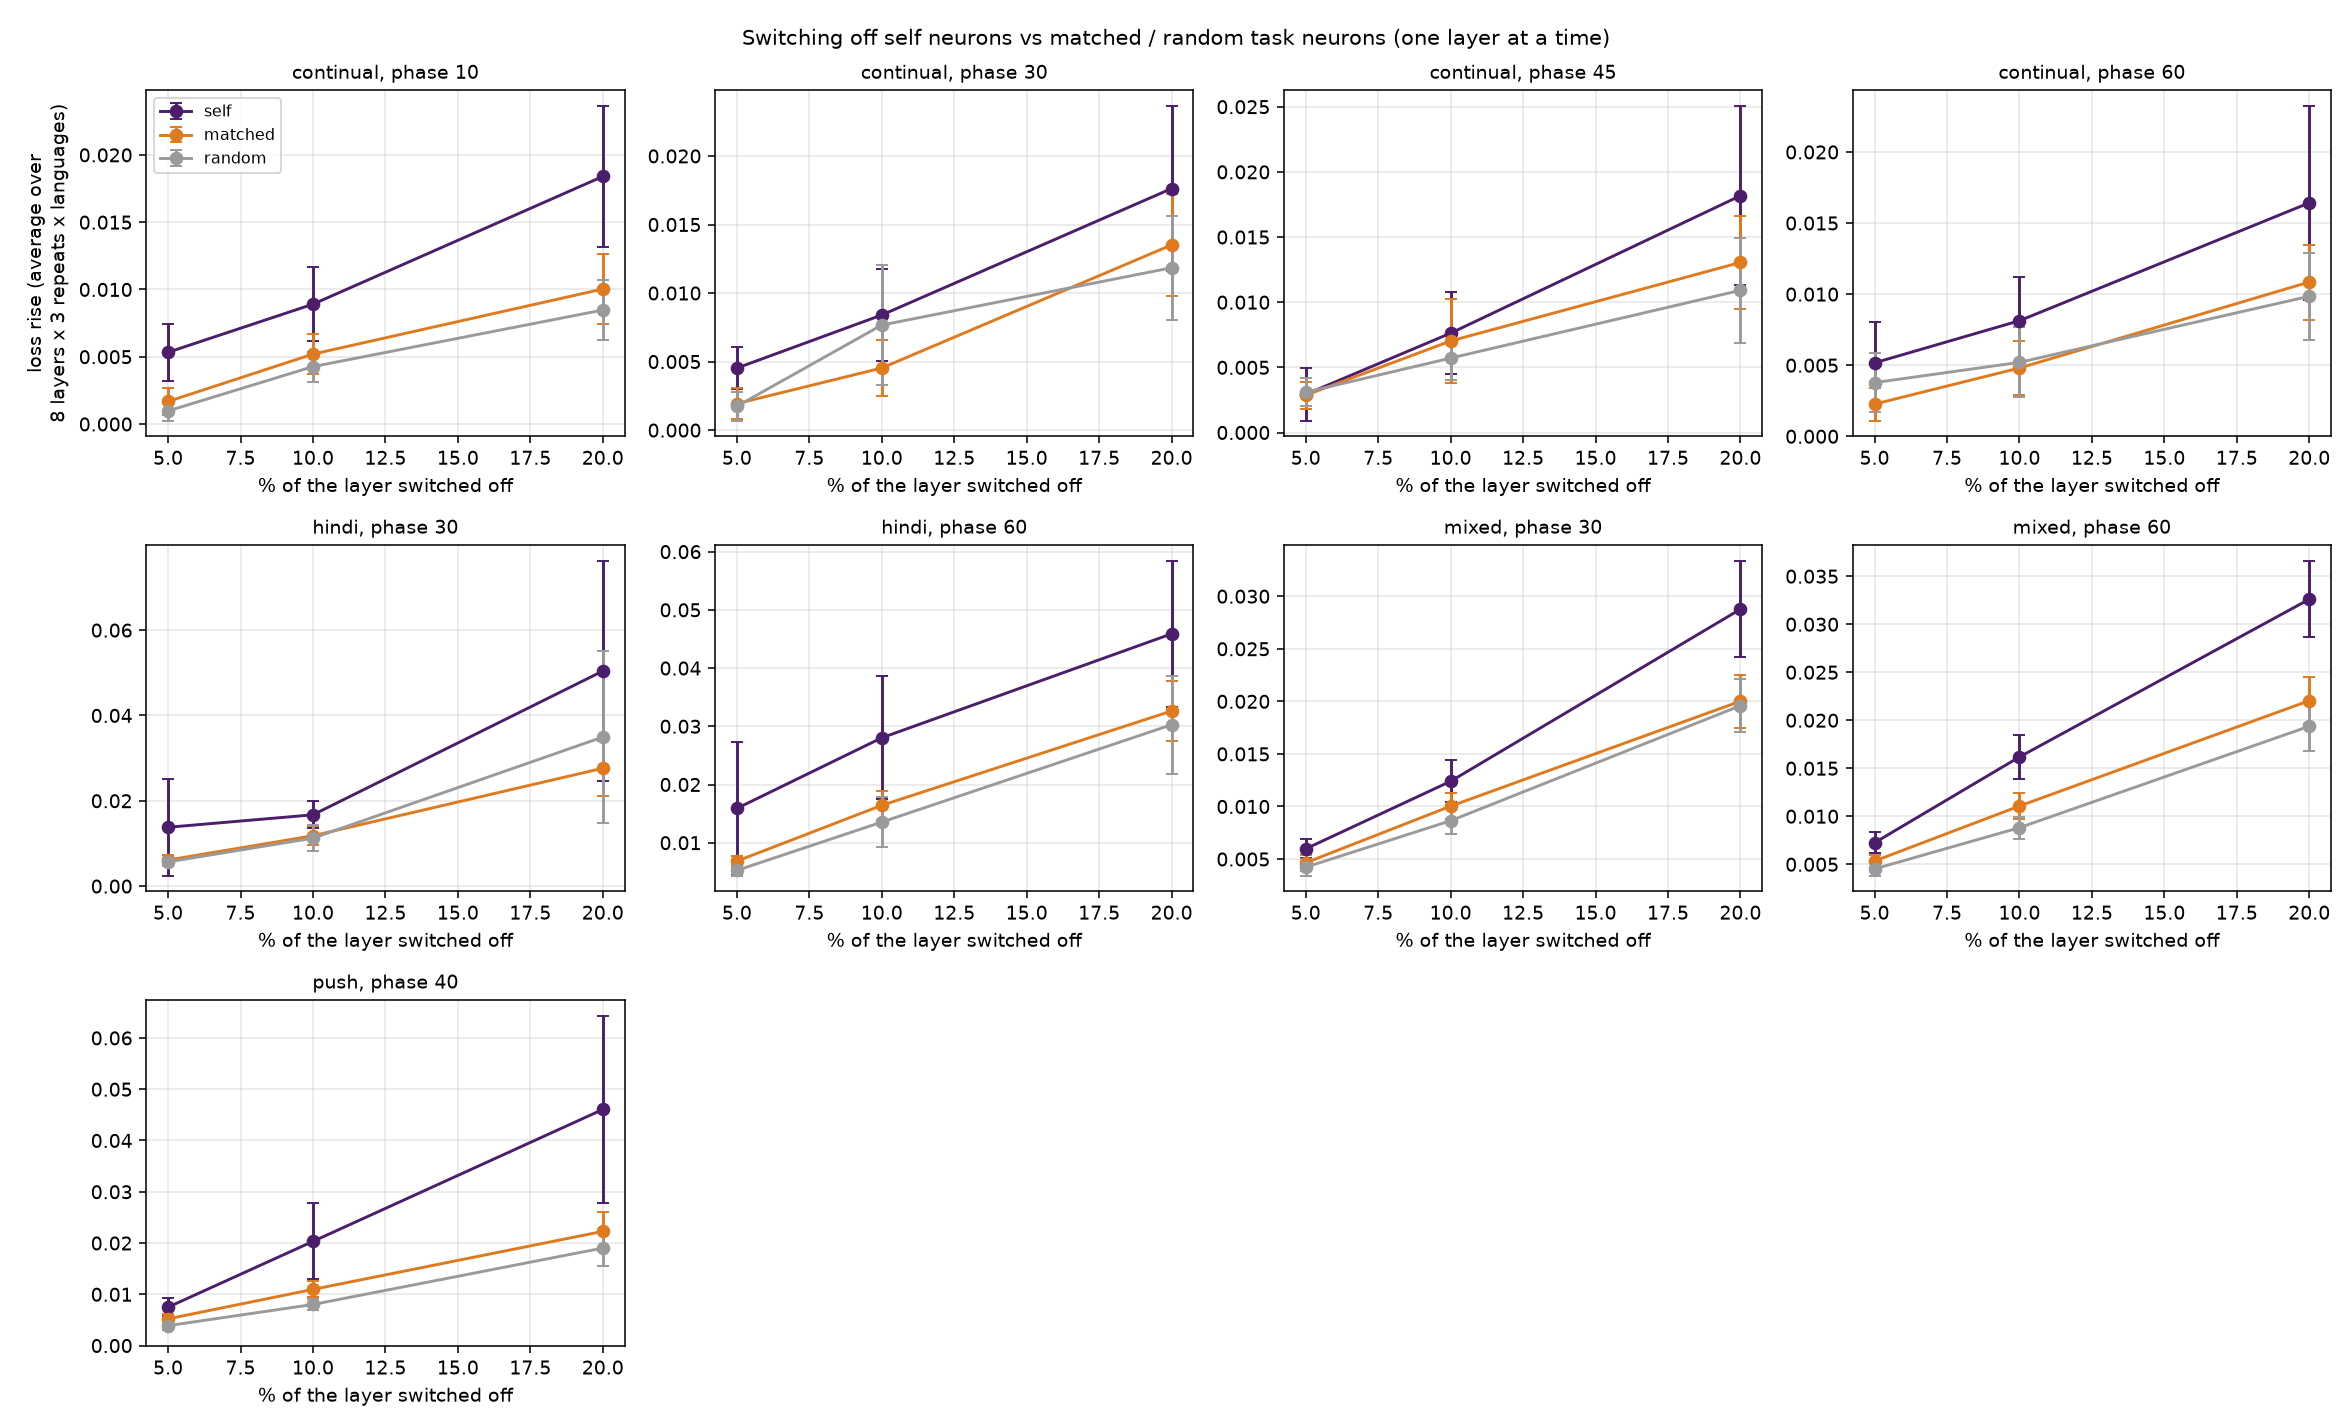

analysis/v8/lesion_distant/ratio_matched.png


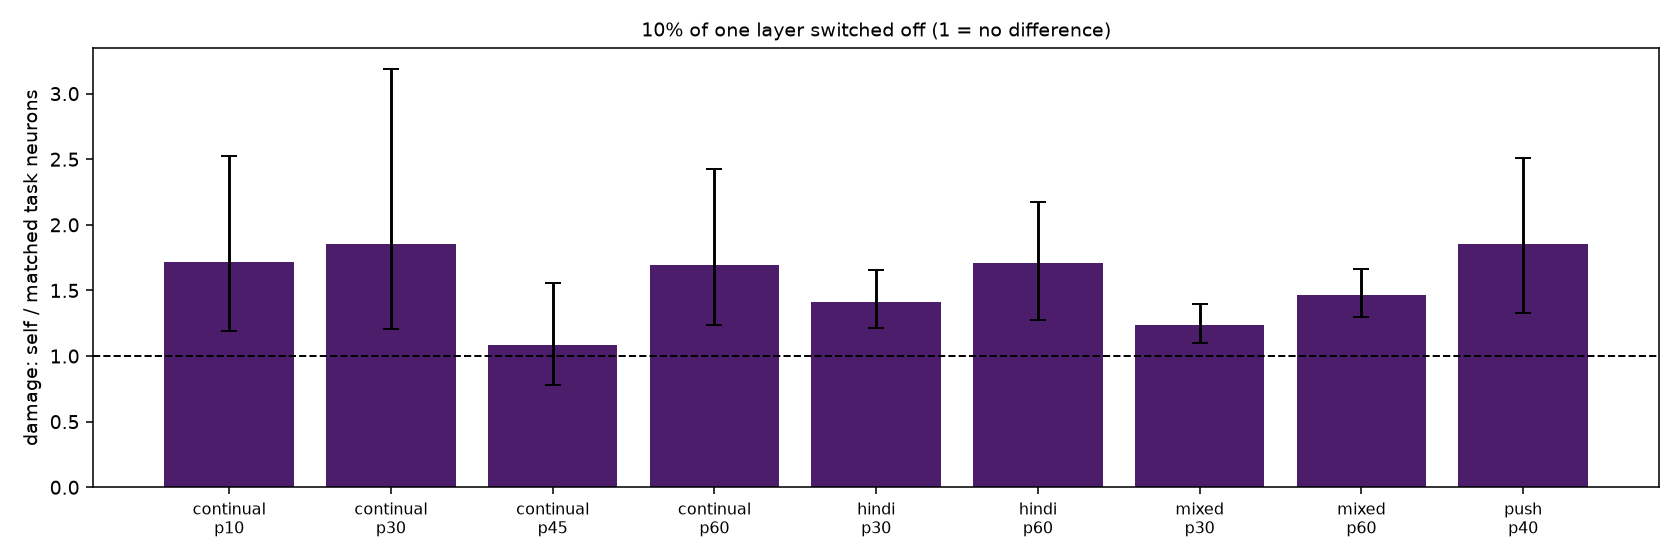

analysis/v8/lesion_indic/dose_response.png


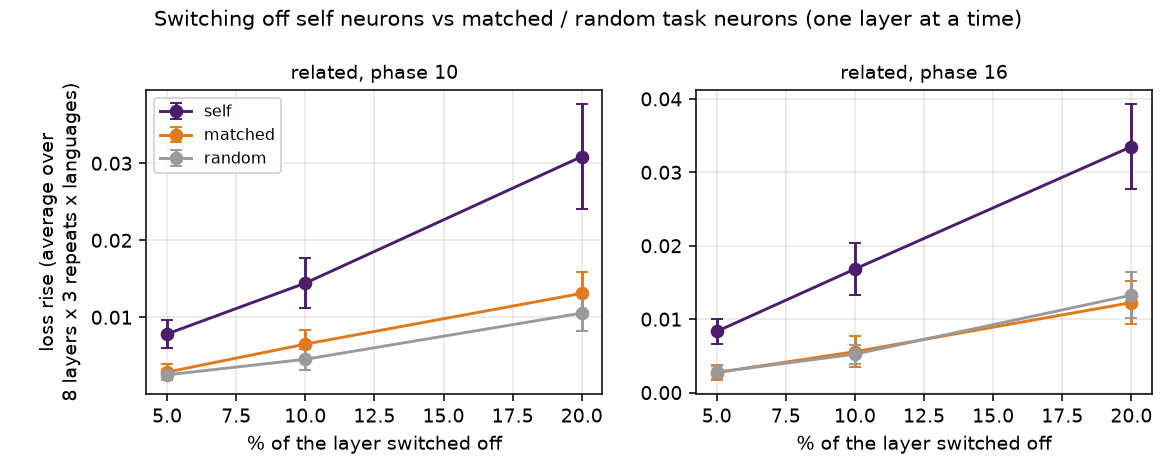

analysis/v8/lesion_indic/ratio_matched.png


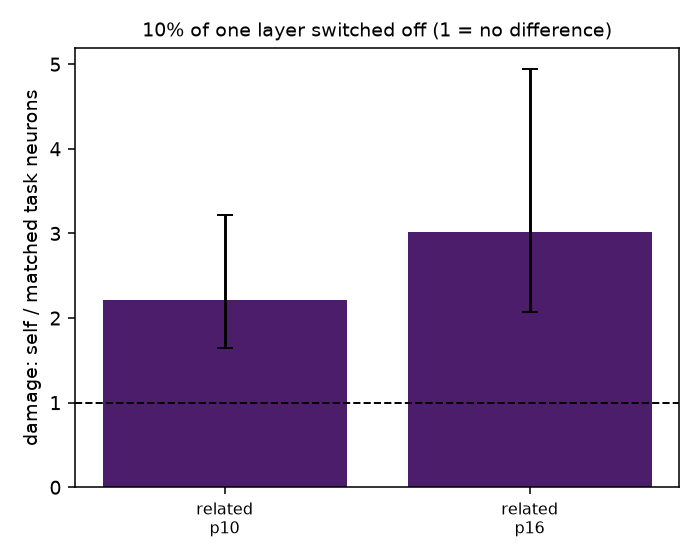

In [8]:
# (5) side by side + figures
run("distant", "--parts", "compare", "--tag", "v8")
for d in ["lesion_distant", "lesion_indic", "related_distant", "related_indic", "compare_v8"]:
    f = f"analysis/v8/{d}/report.txt"
    if os.path.exists(f):
        print("\n" + "=" * 30, d, "=" * 30); print(open(f).read())
for f in sorted(glob.glob("analysis/v8/*/*.png")):
    print(f); display(Image(f))

=== LESION, ALL RESULTS POOLED: 11 checkpoints x 8 layers ===
  one 'cell' = one checkpoint + one layer (averaged over its 3 repeats and its languages)

  10% of one layer, mean ablation:
  EVERYTHING                         self did more damage in 58 of 88 cells (66%, chance would be 50%, p = 1.9e-03) | self / matched 1.68x (95% range 1.39-2.07x)
  model: continual                   self did more damage in 18 of 32 cells (56%, chance would be 50%, p = 3.0e-01) | self / matched 1.53x (95% range 1.05-2.21x)
  model: hindi                       self did more damage in 13 of 16 cells (81%, chance would be 50%, p = 1.1e-02) | self / matched 1.58x (95% range 1.22-2.02x)
  model: mixed                       self did more damage in 11 of 16 cells (69%, chance would be 50%, p = 1.1e-01) | self / matched 1.35x (95% range 1.10-1.65x)
  model: push                        self did more damage in 5 of 8 cells (62%, chance would be 50%, p = 3.6e-01) | self / matched 1.85x (95% range 1.13-2.88x)
  mo

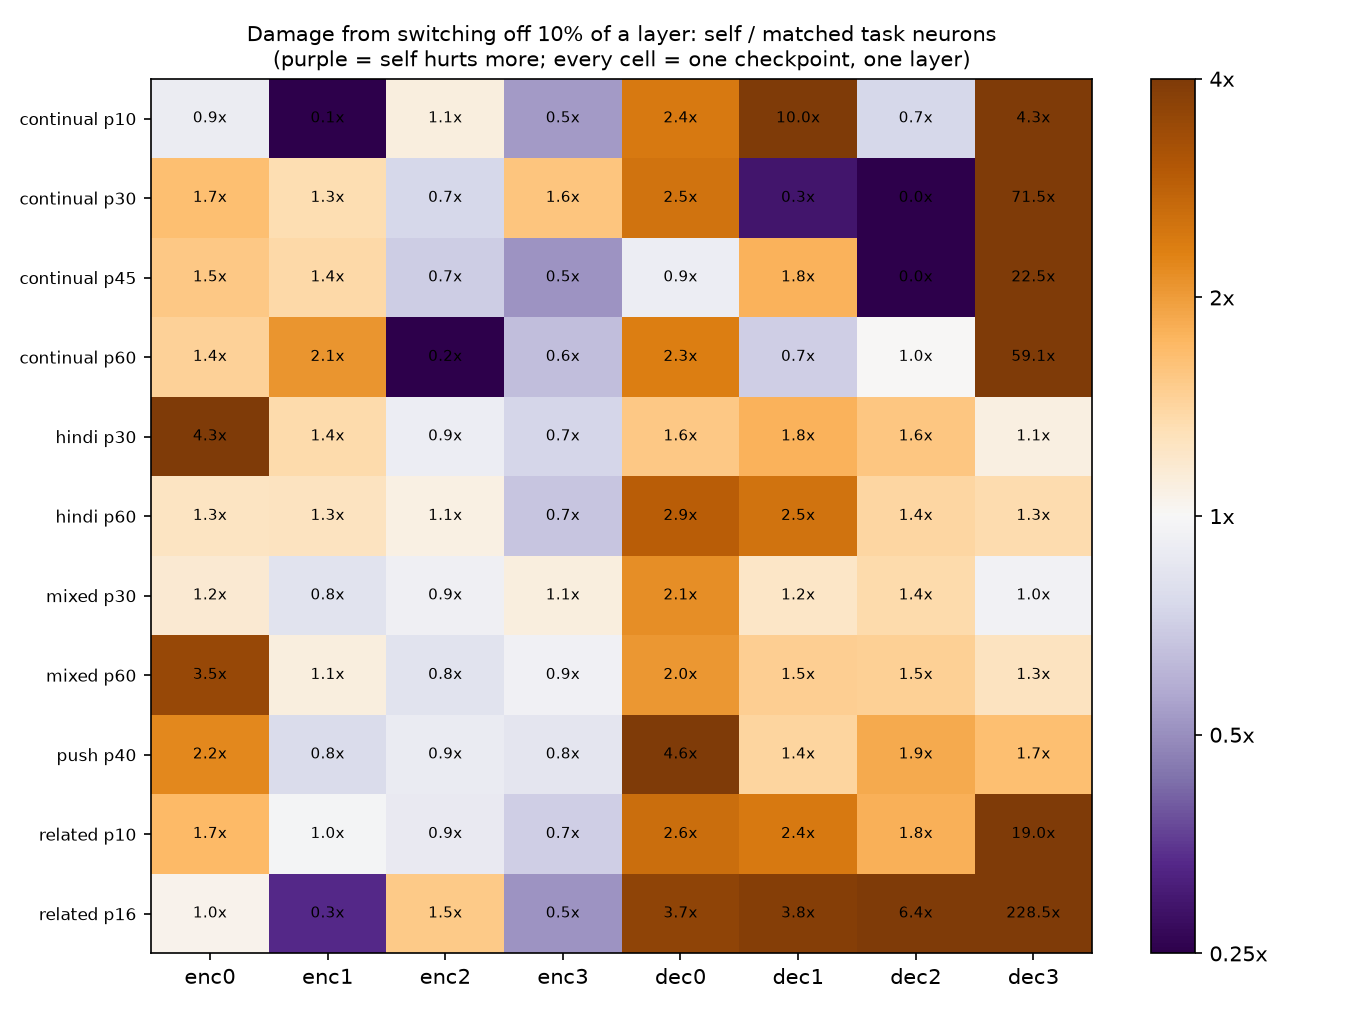

In [9]:
# pooled verdict over every lesion result so far
run("distant", "--parts", "pool", "--tag", "all")
display(Image("analysis/v8/pool_all/every_checkpoint_every_layer.png"))